In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

from pprint import pprint

from functools import partial

import numpy as np
from sklearn.preprocessing import scale
# import sklearn.metrics as metrics
from sklearn.metrics import accuracy_score


import matplotlib.pyplot as plt
import matplotlib.animation as ani

import mlgrad.models as models
import mlgrad.regr as regr
import mlgrad.cls as cls
import mlgrad.pca as pca
import mlgrad.plots as plots
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss
import mlgrad.gd as gd
import mlgrad.smooth as smooth
import mlgrad.inventory as inventory
from mlgrad.af import averaging_function
import mlgrad.avragg as avragg

import rampy
import pybaselines
import random

from irsa import io
from irsa.preprocess import despike, utils
import irsa.widgets as widgets
import irsa.spectra as spectra
import irsa.io as io

import scipy.special as special

import copy

import ipywidgets
from IPython.display import display

import sys
print(sys.version)

# %matplotlib widget

3.13.12 (main, Feb  4 2026, 15:06:39) [GCC 15.2.0]


In [2]:
def plot_params(mod):
    ax = plt.twinx(plt.gca())
    # ax.plot((0,0), (mod.n_param,0), ls='--', lw=0.5, color='b')
    for mod in lfm1.models:
        param1 = np.asarray(mod.param[1:])
        # print(param1[0])
        param_p = param1.copy()
        param_m = param1.copy()
        param_p[param1 < 0] = 0
        param_m[param1 > 0] = 0
        ax.vlines(range(mod.n_input), param_m, param_p, color='k')
    ax.minorticks_on()


In [3]:
path = f"/home/intellimath/YD/repos/spectra/17"
options = {}
dd = {}
# widgets.load_spectra(path, dd, options)

In [67]:
dd = io.load_spectra(path, {"вид_бактерий":["SA", "SS", "SH"], 
                            "номер_цикла":["15"], 
                            "лизис":"термический",
                            # "номер_эксперимента_в_цикле":["2", "4"],
                            # "отсечки_по_молекулярной_массе": ["more100"],                            
                           }, verbose=False)

In [68]:
dd.align_bottom()
dd.crop(400)
dd.scale_by_mean()

In [69]:
dd.drop_zeros_spectrum()
dd.drop_notfinite()
dd.drop_empty()
dd.isfinite()

In [70]:
dd.filter()

In [71]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [72]:
dd.select_baselines(tau2=1.0e7, func=funcs.RStep(0.001, eps=0.001), func2_e=inventory.relative_abs_max)

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [73]:
dd.subtract_baselines(tau2=1.0e7, 
                      func=funcs.RStep(0.001, 0.001),
                      func2_e=inventory.relative_abs_max,
                     )

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_3_термический_20260420_super_SE__H2O(…

In [74]:
dd.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [75]:
dd2 = spectra.SpectraCollection()
for key, sp in dd.spectra.items():
    dd2[key] = sp.robust_averaging(tau=3.5)

In [76]:
dd2.isfinite
dd2.drop_notfinite()
dd2.drop_zeros_spectrum()

In [77]:
dd2.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [78]:
# dd2.plot_mu_sigma()

In [79]:
# dd2.select_for_exclusion()

In [80]:
# dd2.apply(lambda x, y: np.log(y+1))
# dd2.apply(lambda x, y: y+(y.max()-y.min())/(x.max()-x.min())*(x-x.min()))
# dd2.apply(lambda x, y: np.exp(y)-1)

In [22]:
# dd2.scale_by_max()
dd2.scale_by_mean()

In [81]:
dd2.select_baselines(tau2=1.0e5,
                     # func=smooth.func_aspls,
                     func=funcs.RStep(0.001, 0.001), 
                     func2_e=inventory.relative_abs_max,                     
                    )

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [82]:
dd2.subtract_baselines(tau2=1.0e5, 
                      func=funcs.RStep(0.001, 0.001),
                      func2_e=inventory.relative_abs_max,
                     )
dd2.scale_by_mean()

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SA_97__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SH_15__15_5_1_3_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_1_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_2_термический_20260420_super_SE__H2O(…

FloatProgress(value=0.0, bar_style='success', description='SS_17__15_5_1_3_термический_20260420_super_SE__H2O(…

In [23]:
# def subtract_baseline(x, y, tau2=1.0e3):
#     bl = smooth.whittaker_smooth(
#         y,
#         func=funcs.RStep(0.001, eps=0.001),
#         # func2=funcs.RStep(0.001, eps=0.001),
#         func2_e=inventory.relative_abs_max,
#         tau2=tau2, d=2)
#     y -= bl
#     y /= abs(y).mean()
#     return y

# dd2.apply(subtract_baseline, inplace=True)

In [27]:
dd2.save("/home/intellimath/work/spectra/17.1_termo", "rm_bl")

In [28]:
dd2 = spectra.SpectraCollection()
dd2.load("/home/intellimath/work/spectra/17.1_termo", "rm_bl")

In [83]:
dd2.plot_spectra()

interactive(children=(Dropdown(description='Spectra key:', layout=Layout(width='75%'), options=('SA_97__15_5_1…

In [84]:
dd_SA = dd2.subcollection_by_attr_value("вид_бактерий", "SA")
dd_SS = dd2.subcollection_by_attr_value("вид_бактерий", "SS")
dd_SH = dd2.subcollection_by_attr_value("вид_бактерий", "SH")

Ys_SA = dd_SA.union_y()
Ys_SS = dd_SS.union_y()
Ys_SH = dd_SH.union_y()
Ys = dd2.union_y()
print(len(Ys_SA), len(Ys_SS), len(Ys_SH))

60 60 60


In [85]:
# dd_SA.plot_spectra(False)

In [86]:
# dd2.plot_mu_sigma()

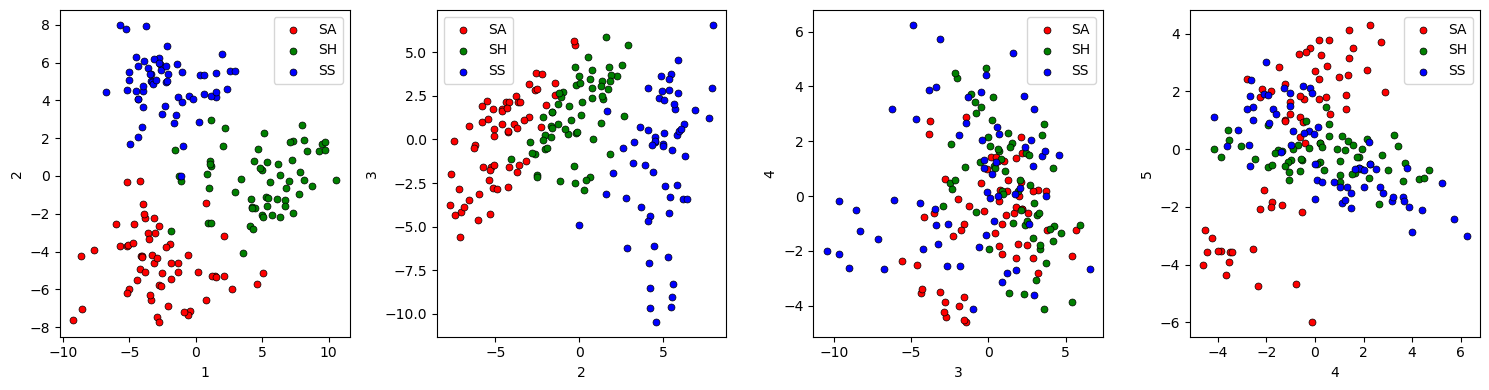

In [87]:
c, As, Ls = pca.find_loc_and_pc(Ys, 5)
U = (Ys - c) @ As.T
U_SA = (Ys_SA - c) @ As.T
U_SS = (Ys_SS - c) @ As.T
U_SH = (Ys_SH - c) @ As.T
plt.figure(figsize=(15,4))
for i in range(4):
    plt.subplot(1,4,i+1)
    plt.scatter(U_SA[:,i], U_SA[:,i+1], s=25, c='r', edgecolors='k', linewidth=0.5, label="SA")
    plt.scatter(U_SH[:,i], U_SH[:,i+1], s=25, c='g', edgecolors='k', linewidth=0.5, label="SH")
    plt.scatter(U_SS[:,i], U_SS[:,i+1], s=25, c='b', edgecolors='k', linewidth=0.5, label="SS")
    plt.xlabel(str(i+1))
    plt.ylabel(str(i+2))
    # plt.xticks([])
    # plt.yticks([])
    plt.legend()
plt.tight_layout()
plt.legend()
plt.show()

# Ls /= Ls.sum()
# plt.figure(figsize=(10,3))
# plt.plot(Ls, marker='o')
# plt.grid(ls=':', lw=0.5)
# plt.minorticks_on()
# plt.show()

In [88]:
# dd2.plot_spectra()

In [89]:
# dd2.plot_mu_sigma()

In [90]:
import mlgrad.models as models
import mlgrad.funcs as funcs
import mlgrad.funcs2 as funcs2
import mlgrad.loss as loss

import mlgrad.regr as regr
import mlgrad.af as af

Zs_SS = np.ones(Ys_SS.shape[0])
Zs_SH = np.ones(Ys_SH.shape[0])
Zs_SA = np.ones(Ys_SA.shape[0])

ys = np.concatenate((Ys_SS, Ys_SH, Ys_SA), axis=0)
zs = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA), axis=0)

ys1 = np.concatenate((Ys_SS,Ys_SH), axis=0)
zs1 = np.concatenate((Zs_SS,-Zs_SH), axis=0)
ys1 = np.ascontiguousarray(ys1)
zs1 = np.ascontiguousarray(zs1)

ys2 = np.concatenate((Ys_SH,Ys_SA), axis=0)
zs2 = np.concatenate((Zs_SH,-Zs_SA), axis=0)
ys2 = np.ascontiguousarray(ys2)
zs2 = np.ascontiguousarray(zs2)

ys3 = np.concatenate((Ys_SA,Ys_SS), axis=0)
zs3 = np.concatenate((Zs_SA,-Zs_SS), axis=0)
ys3 = np.ascontiguousarray(ys3)
zs3 = np.ascontiguousarray(zs3)

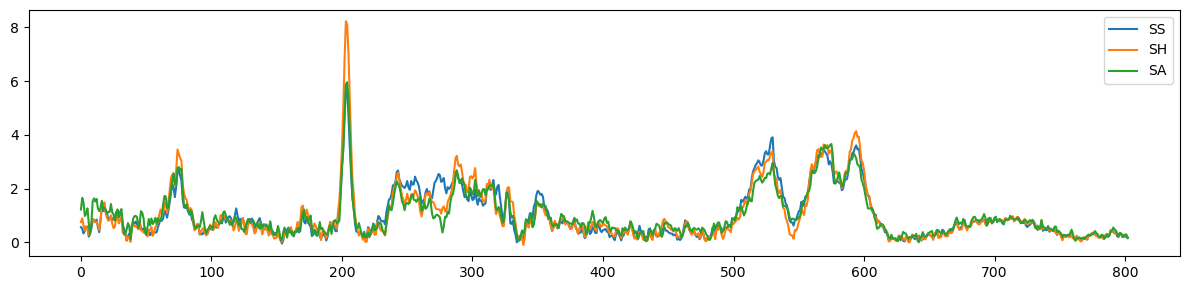

In [91]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plt.tight_layout()
plt.show()

In [92]:
import joblib

@joblib.delayed
#@joblib.wrap_non_picklable_objects
def fit_snm(ys, zs, weights, tau=0, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    mod = models.SigmaNeuronModel(funcs.Sigmoidal(sigma), ys.shape[1])
    mod.allocate()
    mod.init_param()
    mod.use_regularizer(funcs2.AbsoluteNorm(), tau)

    if p_threshold != 0:
        projector = gd.Masked(mod, p_threshold)
    else:
        projector = None

    for _ in range(n_try):
        mod.init_param()

        alg = regr.regression(ys, zs, mod,
                              loss_func=loss.ErrorLoss(funcs.SoftAbs_Sqrt(0.001)),
                              # loss_func=loss.ErrorLoss(funcs.Abs()),
                              # regnorm=funcs2.AbsoluteNorm(),
                              projector=projector, 
                              weights=weights,
                              h=0.002, n_iter=1000)
        w = accuracy_score(zs, np.sign(mod.evaluate(ys)))
        if w >= accuracy_min:
            break
    return mod, w

def fit_lfm(ys, zs, tau=0, *, n_model=45, accuracy_min=0.75, n_try=5, sigma=10.0, p_threshold=1.0e-4):
    Np = (zs>0).sum()
    Nm = (zs<0).sum()
    N = Np + Nm
    
    weights = np.zeros(N)
    weights[zs > 0] = Nm / N
    weights[zs < 0] = Np / N

    with joblib.Parallel(n_jobs=2, max_nbytes=None, batch_size=1) as parallel:
        results = parallel( 
            [fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma) for i in range(n_model)]
        )

    lfm = models.LinearFuncModel()
    for mod, w in results:
    # for i in range(n_model):
    #     mod, w = fit_snm(ys, zs, weights, tau=tau, accuracy_min=accuracy_min, n_try=n_try, sigma=sigma, p_threshold=p_threshold)
        lfm.add(mod, w)

    inventory.normalize(lfm.weights.asarray())
    return lfm

#### SS/SH

In [96]:
lfm1 = fit_lfm(ys1, zs1, tau=350.0)
print(accuracy_score(zs1, np.sign(lfm1.evaluate(ys1))))

1.0


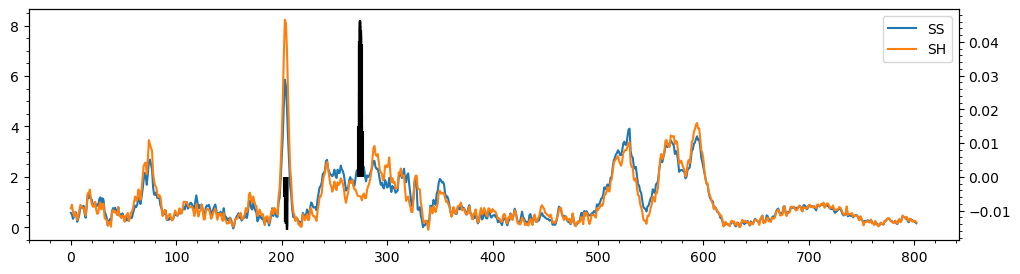

In [97]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.minorticks_on()
plt.legend()
plot_params(lfm1)
plt.show()
# print(np.asarray(lfm1.models[0].param))

In [98]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm1, ys1, zs1)

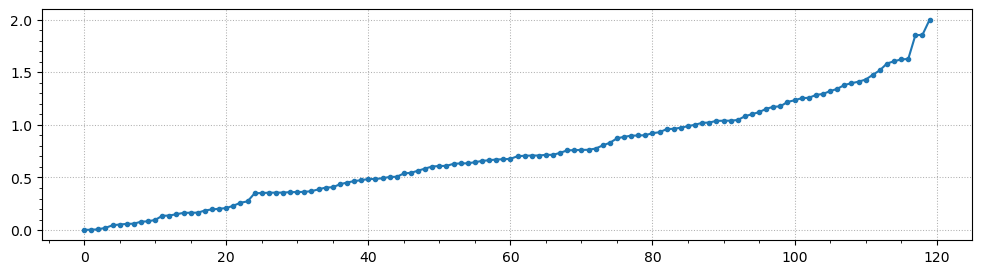

In [99]:
plt.figure(figsize=(12,3))
plt.plot(sorted(abs(inventory.modified_zscore(zs1*lfm1.evaluate(ys1)))), marker='o', ms=3)
plt.grid(ls=':', lw=0.75)
plt.minorticks_on()
plt.show()

### SH / SA

In [104]:
lfm2 = fit_lfm(ys2, zs2, tau=70.0)
print(accuracy_score(zs2, np.sign(lfm2.evaluate(ys2))))

1.0


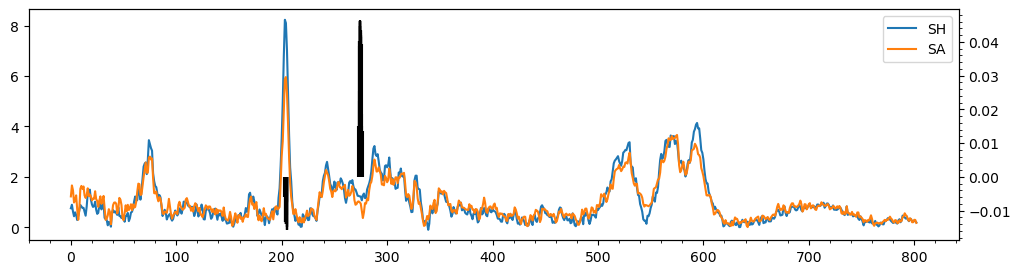

In [105]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SH.mean(axis=0), label="SH")
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.legend()
plot_params(lfm2)
plt.show()

In [69]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm2, ys2, zs2)

In [70]:
# plt.figure(figsize=(12,3))
# plt.plot(sorted(abs(inventory.modified_zscore(zs2*lfm2.evaluate(ys2)))), marker='o', ms=3)
# # plt.plot(sorted(zs2*lfm2.evaluate(ys2)), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

### SA / SS

In [109]:
lfm3 = fit_lfm(ys3, zs3, tau=300.0)
print(accuracy_score(zs3, np.sign(lfm3.evaluate(ys3))))

1.0


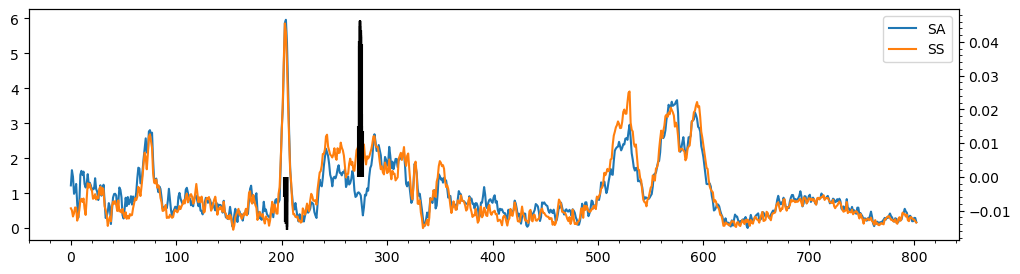

In [110]:
plt.figure(figsize=(12,3))
plt.plot(Ys_SA.mean(axis=0), label="SA")
plt.plot(Ys_SS.mean(axis=0), label="SS")
plt.legend()
plot_params(lfm3)
plt.show()

In [111]:
# plt.figure(figsize=(10,3))
# plots.plot_cls_function(lfm3, ys3, zs3)

In [112]:
# plt.figure(figsize=(12,3))\
# plt.plot(sorted(abs(inventory.modified_zscore(zs3*lfm3.evaluate(ys3)))), marker='o', ms=3)
# plt.grid(ls=':', lw=0.75)
# plt.minorticks_on()
# plt.show()

180
60
60
80


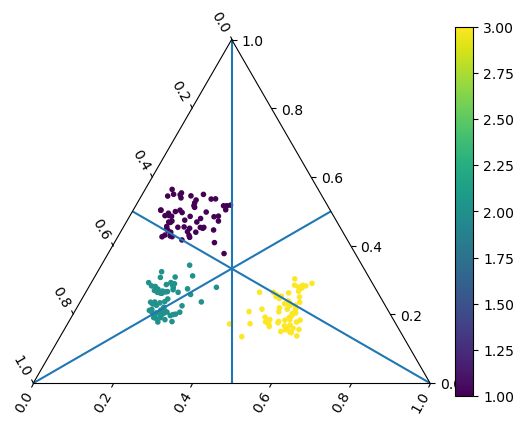

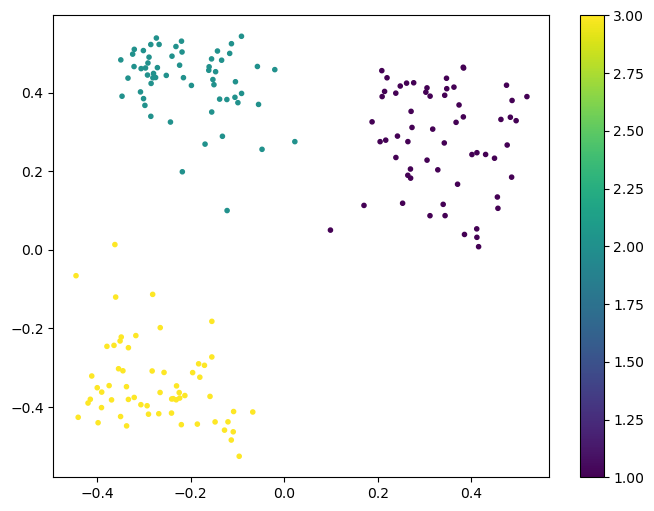

In [113]:
import mpltern
print(len(ys))

ax = plt.subplot(projection="ternary")
Z1 = lfm1.evaluate(ys)
Z2 = lfm2.evaluate(ys)
Z3 = lfm3.evaluate(ys)
Y1 = (1 + (Z1 - Z3) / 2) / 2
Y2 = (1 + (Z2 - Z1) / 2) / 2
Y3 = (1 + (Z3 - Z2) / 2) / 2
Y1[Y1<0] = 0
Y2[Y2<0] = 0
Y3[Y3<0] = 0
print(((Z1>0) & (Z3<0)).sum())
print(((Z2>0) & (Z1<0)).sum())
print(((Z2>0) & (Z3<0)).sum())
# print(Y1)
# print(Y2)
# print(Y3)
C = [(y1,y2,y3) for y1,y2,y3 in zip(Y1,Y2,Y3)]
# cax = ax.inset_axes([1.05, 0.1, 0.05, 0.9], transform=ax.transAxes)
cs = ax.scatter(Y1, Y2, Y3, c=zs, s=9)
plt.colorbar(cs)
ax.axline(
    [0.5, 0.0, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.5, 0.0],
    [0.5, 0.5, 0.5])
ax.axline(
    [0.0, 0.0, 0.5],
    [0.5, 0.5, 0.5])
plt.show()

zz1 = Y1
zz2 = Y2 * np.exp(2j/3 * np.pi)
zz3 = Y3 * np.exp(-2j/3 * np.pi)
C = np.concatenate((Zs_SS, 2*Zs_SH, 3*Zs_SA))
plt.figure(figsize=(8,6))
cs = plt.scatter(np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3), s=9, c=C)
plt.colorbar(cs)
plt.show()


In [114]:
from sklearn.linear_model import LogisticRegression

XX = np.c_[np.real(zz1+zz2+zz3), np.imag(zz1+zz2+zz3)]
YY = np.concatenate((Zs_SS-1, Zs_SH, 2*Zs_SA))

lrg = LogisticRegression()
lrg.fit(XX, YY)

print(accuracy_score(YY, lrg.predict(XX)))

1.0
